# 03 · Analysis: does a foundation-model encoder transfer better across biomes?

This notebook **only reads the CSV files** written by `02_train.ipynb` (`results/raw/runs/*.csv`, `results/raw/per_image/*.csv`).
It never loads images or models, so the analysis cannot influence training. It runs on a CPU in seconds.

Every number below is computed from per-image confusion counts (TP, FP, FN, TN, forest = positive), which makes it possible to
report the metric of each earlier study on the same predictions:

| metric | definition | used by |
|---|---|---|
| **mIoU** (main) | mean of the forest IoU and the non-forest IoU, pixels pooled over the test set | this work |
| weighted IoU / F1 | per-class IoU / F1 averaged with weights = share of true pixels of each class | John & Zhang (2022) |
| per-image F1 | forest F1 of each test image, then mean ± SD over the images | Benvenuto et al. (2025) |
| κ, MCC, balanced accuracy, area bias | chance-corrected agreement / class-balanced scores / forest-share error | remote-sensing practice |
| ROC AUC, average precision, ECE (20-bin) | threshold-free ranking quality and calibration, from 20-bin probability histograms | — |

**Caveat on the 20-bin metrics.** Pixels that fall in the same probability bin count as ties, and confident models put most pixels
in the first and last bin, so the binned AUC/AP are slightly *below* the exact values (by up to a few hundredths) and the gap grows
with confidence. Differences of about 0.01 or less between models in these columns are not interpretable. Exact values can be
recomputed from the saved checkpoints without retraining.

**Per-image F1:** images without forest in both the mask and the prediction have an undefined F1 and are left out of the mean.
| boundary F1 | F1 of predicted vs. true class boundaries with 2-pixel tolerance | — |

Only **complete seeds** are used: a seed counts only if every model has finished it for both training biomes.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RESULTS = Path(os.environ.get("RESULTS_DIR", "../results"))
RAW, TABLES, FIGS = RESULTS / "raw", RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 200)

MODEL_ORDER = ["unet_ft", "unet_pft", "dinov2_ft", "dinov2_pft", "dinov3_ft", "dinov3_pft", "dinov3l_pft", "dinov3sat_pft"]
MODEL_NAMES = {"unet_ft": "U-Net ResNet-34, full", "unet_pft": "U-Net ResNet-34, partial",
               "dinov2_ft": "DINOv2 ViT-S, full", "dinov2_pft": "DINOv2 ViT-S, partial",
               "dinov3_ft": "DINOv3 ViT-S, full", "dinov3_pft": "DINOv3 ViT-S, partial",
               "dinov3l_pft": "DINOv3 ViT-L web, partial", "dinov3sat_pft": "DINOv3 ViT-L sat, partial"}
COLORS = {"unet": "#2a78d6", "dinov2": "#eb6834", "dinov3": "#1baf7a", "dinov3l": "#8a4fd0", "dinov3sat": "#d9a400"}
BIOME = {"amazon": "Amazon", "atlantic": "Atlantic Forest"}
DIRECTIONS = [("amazon", "amazon_test"), ("amazon", "atlantic_test"), ("atlantic", "atlantic_test"), ("atlantic", "amazon_test")]
def dir_name(train, ev):
    return f"{BIOME[train]} → {BIOME[ev.split('_')[0]]}" + (" (all)" if ev.endswith("_all") else "")

runs = pd.concat([pd.read_csv(f) for f in sorted((RAW / "runs").glob("*.csv"))], ignore_index=True)
pix = pd.concat([pd.read_csv(f) for f in sorted((RAW / "per_image").glob("*.csv"))], ignore_index=True)
runs = runs[~runs.smoke_test.astype(bool)]
# Guard against smoke-test or stray runs that share run ids with real ones: keep only the main schedule (most common number of
# epochs) and the full step count per training biome, and require one parameter count per model.
EPOCHS = runs.epochs.mode()[0]
runs = runs[runs.epochs == EPOCHS]
runs = runs[runs.steps == runs.groupby("train_biome").steps.transform("max")]
assert (runs.groupby("model").total_params.nunique() == 1).all(), "different parameter counts within a model: mixed runs?"
models = [m for m in MODEL_ORDER if m in set(runs.model)]

# complete seeds: every selected model, both training biomes
need = {(m, b) for m in models for b in BIOME}
complete = sorted(s for s, g in runs.groupby("seed") if need <= set(zip(g.model, g.train_biome)))
runs = runs[runs.seed.isin(complete)]
pix = pix[pix.run.isin(set(runs.run))]
print(f"{len(runs)} runs, models: {models}, complete seeds: {complete}")
print("GPUs:", runs.gpu.value_counts().to_dict())

80 runs, models: ['unet_ft', 'unet_pft', 'dinov2_ft', 'dinov2_pft', 'dinov3_ft', 'dinov3_pft', 'dinov3l_pft', 'dinov3sat_pft'], complete seeds: [0, 1, 2, 3, 4]
GPUs: {'NVIDIA GeForce RTX 4090': 80}


## 1. Metrics per run

In [2]:
HF = [c for c in pix.columns if c.startswith("hist_forest_")]
HN = [c for c in pix.columns if c.startswith("hist_nonforest_")]
EDGES = np.linspace(0, 1, len(HF) + 1)

def threshold_free(hf, hn):
    """ROC AUC, average precision and expected calibration error from probability histograms (forest = positive).
    Ties inside a bin are resolved by the trapezoid rule (AUC) or treated as one threshold (AP)."""
    hf, hn = np.asarray(hf, float), np.asarray(hn, float)
    P, N = hf.sum(), hn.sum()
    tp = np.cumsum(hf[::-1])[::-1]          # forest pixels with p >= lower edge of bin i (threshold = that edge)
    fp = np.cumsum(hn[::-1])[::-1]
    tpr = np.concatenate([tp / P, [0.0]]); fpr = np.concatenate([fp / N, [0.0]])
    auc = float(-np.trapezoid(tpr, fpr))
    prec = tp / np.maximum(tp + fp, 1); rec = tp / P
    ap = float(np.sum((rec - np.concatenate([rec[1:], [0.0]])) * prec))
    centers = (EDGES[:-1] + EDGES[1:]) / 2; n_bin = hf + hn
    ece = float(np.sum(n_bin * np.abs(hf / np.maximum(n_bin, 1) - centers)) / (P + N))   # bin-centre approximation
    return auc, ap, ece

def pooled(g):
    """All metrics of one run on one evaluation set, pooled over its images."""
    tp, fp, fn, tn = (g[c].sum().astype(float) for c in ("tp", "fp", "fn", "tn"))
    n = tp + fp + fn + tn
    iou_f, iou_n = tp / (tp + fp + fn), tn / (tn + fn + fp)
    f1_f, f1_n = 2 * tp / (2 * tp + fp + fn), 2 * tn / (2 * tn + fn + fp)
    w_f = (tp + fn) / n                                         # share of true forest pixels
    acc = (tp + tn) / n
    p_e = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2
    mcc = (tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    per_img_f1 = 2 * g.tp / (2 * g.tp + g.fp + g.fn).replace(0, np.nan)
    out = dict(miou=(iou_f + iou_n) / 2, iou_forest=iou_f, iou_nonforest=iou_n,
               w_iou=w_f * iou_f + (1 - w_f) * iou_n, w_f1=w_f * f1_f + (1 - w_f) * f1_n, f1_forest=f1_f,
               precision=tp / (tp + fp), recall=tp / (tp + fn), acc=acc,
               balanced_acc=0.5 * (tp / (tp + fn) + tn / (tn + fp)), kappa=(acc - p_e) / (1 - p_e), mcc=mcc,
               area_bias=(tp + fp - tp - fn) / n,               # predicted minus true forest share
               img_f1=per_img_f1.mean(), img_f1_sd=per_img_f1.std(), n_images=len(g))
    if HF:
        out["auroc"], out["ap"], out["ece"] = threshold_free(g[HF].sum(), g[HN].sum())
    if "bnd_pred" in g:
        bp = g.bnd_pred_matched.sum() / max(g.bnd_pred.sum(), 1); br = g.bnd_true_matched.sum() / max(g.bnd_true.sum(), 1)
        out["boundary_f1"] = 2 * bp * br / max(bp + br, 1e-9)
    return pd.Series(out)

M = pix.groupby(["model", "seed", "train_biome", "eval_set"]).apply(pooled, include_groups=False).reset_index()
M.to_csv(TABLES / "metrics_per_run.csv", index=False)
M.head()

,model,seed,train_biome,eval_set,miou,iou_forest,iou_nonforest,w_iou,w_f1,f1_forest,...,kappa,mcc,area_bias,img_f1,img_f1_sd,n_images,auroc,ap,ece,boundary_f1
0,dinov2_ft,0,amazon,amazon_test,0.960255,0.960456,0.960054,0.960256,0.979725,0.979829,...,0.959449,0.959452,0.001216,0.973947,0.019617,20.0,0.995962,0.994053,0.023373,0.933403
1,dinov2_ft,0,amazon,atlantic_all,0.825200,0.774080,0.876320,0.842467,0.913744,0.872655,...,0.806824,0.807617,0.019920,0.830936,0.132938,605.0,0.953310,0.876156,0.043039,0.853570
2,dinov2_ft,0,amazon,atlantic_test,0.814579,0.755362,0.873795,0.836506,0.909974,0.860634,...,0.793394,0.794383,0.021922,0.836068,0.113843,20.0,0.950102,0.857698,0.047581,0.866774
3,dinov2_ft,0,atlantic,amazon_all,0.919190,0.922772,0.915607,0.919381,0.957994,0.959835,...,0.915784,0.915879,-0.007169,0.939680,0.086112,619.0,0.982877,0.978051,0.019036,0.835346
4,dinov2_ft,0,atlantic,amazon_test,0.934551,0.934191,0.934910,0.934549,0.966168,0.965976,...,0.932343,0.932515,-0.009622,0.955556,0.036788,20.0,0.987126,0.983146,0.020785,0.865567


## 2. Main table: in-biome vs. cross-biome (official test sets, mean ± SD over seeds)

In [3]:
def mean_sd(x, d=3):
    return f"{x.mean():.{d}f} ± {x.std(ddof=1):.{d}f}" if len(x) > 1 else f"{x.mean():.{d}f}"

rows = []
for m in models:
    row = {"model": MODEL_NAMES[m]}
    for tb, ev in DIRECTIONS:
        x = M[(M.model == m) & (M.train_biome == tb) & (M.eval_set == ev)].miou
        row[dir_name(tb, ev)] = mean_sd(x)
    a2f = M[(M.model == m) & (M.train_biome == "amazon") & (M.eval_set == "atlantic_test")].set_index("seed").miou
    f2f = M[(M.model == m) & (M.train_biome == "atlantic") & (M.eval_set == "atlantic_test")].set_index("seed").miou
    row["transfer gap (Atlantic test)"] = mean_sd(f2f - a2f)
    rows.append(row)
T1 = pd.DataFrame(rows)
T1.to_csv(TABLES / "table1_miou.csv", index=False)
print(f"mIoU, official test sets, {len(complete)} seeds")
display(T1)

mIoU, official test sets, 5 seeds


,model,Amazon → Amazon,Amazon → Atlantic Forest,Atlantic Forest → Atlantic Forest,Atlantic Forest → Amazon,transfer gap (Atlantic test)
0,"U-Net ResNet-34, full",0.964 ± 0.001,0.807 ± 0.009,0.926 ± 0.002,0.918 ± 0.007,0.119 ± 0.008
1,"U-Net ResNet-34, partial",0.962 ± 0.002,0.814 ± 0.004,0.929 ± 0.000,0.924 ± 0.006,0.115 ± 0.004
2,"DINOv2 ViT-S, full",0.960 ± 0.001,0.816 ± 0.003,0.924 ± 0.001,0.933 ± 0.007,0.109 ± 0.002
3,"DINOv2 ViT-S, partial",0.958 ± 0.001,0.816 ± 0.007,0.923 ± 0.001,0.938 ± 0.003,0.107 ± 0.008
4,"DINOv3 ViT-S, full",0.964 ± 0.001,0.816 ± 0.007,0.931 ± 0.002,0.929 ± 0.005,0.115 ± 0.006
5,"DINOv3 ViT-S, partial",0.962 ± 0.002,0.811 ± 0.006,0.930 ± 0.001,0.934 ± 0.006,0.119 ± 0.007
6,"DINOv3 ViT-L web, partial",0.965 ± 0.000,0.819 ± 0.011,0.932 ± 0.001,0.923 ± 0.004,0.113 ± 0.010
7,"DINOv3 ViT-L sat, partial",0.965 ± 0.001,0.802 ± 0.013,0.933 ± 0.000,0.921 ± 0.011,0.131 ± 0.014


**Reading the table.** The diagonal directions (Amazon → Amazon, Atlantic → Atlantic) are the in-biome scores that earlier work
reports; they are expected to be close to saturation. The question is answered in the **Amazon → Atlantic Forest** column and in
the transfer gap (Atlantic-trained minus Amazon-trained model on the same Atlantic test images): a smaller gap means better transfer.
The two models of a gap are independent trainings (same seed number, different data), so its SD is effectively unpaired.

## 3. Larger transfer test: the whole other biome

The official test sets have only 20 images per biome. A model trained on one biome has never seen *any* image of the other one,
so the whole other biome (train + val + test: 605 Atlantic Forest or 619 Amazon images) is a valid and 30× larger transfer test set.

In [4]:
rows = []
for m in models:
    row = {"model": MODEL_NAMES[m]}
    for tb, ev in [("amazon", "atlantic_all"), ("atlantic", "amazon_all")]:
        x = M[(M.model == m) & (M.train_biome == tb) & (M.eval_set == ev)].miou
        row[dir_name(tb, ev)] = mean_sd(x)
    rows.append(row)
T2 = pd.DataFrame(rows)
T2.to_csv(TABLES / "table2_miou_whole_biome.csv", index=False)
display(T2)

,model,Amazon → Atlantic Forest (all),Atlantic Forest → Amazon (all)
0,"U-Net ResNet-34, full",0.814 ± 0.007,0.891 ± 0.011
1,"U-Net ResNet-34, partial",0.820 ± 0.003,0.905 ± 0.009
2,"DINOv2 ViT-S, full",0.823 ± 0.003,0.899 ± 0.012
3,"DINOv2 ViT-S, partial",0.824 ± 0.005,0.909 ± 0.009
4,"DINOv3 ViT-S, full",0.818 ± 0.007,0.901 ± 0.010
5,"DINOv3 ViT-S, partial",0.814 ± 0.005,0.907 ± 0.012
6,"DINOv3 ViT-L web, partial",0.822 ± 0.013,0.899 ± 0.008
7,"DINOv3 ViT-L sat, partial",0.806 ± 0.010,0.881 ± 0.018


## 3b. All metrics for the transfer directions

Mean over seeds. Besides the overlap metrics: Cohen's κ and MCC (chance-corrected, robust to the 33/67 class split of the Atlantic
Forest), balanced accuracy, **area bias** (predicted minus true forest share, the quantity a forest monitor reports), the
threshold-free **ROC AUC** and **average precision** (does the encoder rank pixels well even if the 0.5 threshold is off on the new
biome?), the **expected calibration error**, and the **boundary F1** (2-pixel tolerance; transfer errors often sit at forest edges).

In [5]:
SECONDARY = ["miou", "w_iou", "f1_forest", "precision", "recall", "balanced_acc", "kappa", "mcc", "area_bias",
             "auroc", "ap", "ece", "boundary_f1", "img_f1"]
SECONDARY = [c for c in SECONDARY if c in M.columns]
for tb, ev in [("amazon", "atlantic_test"), ("amazon", "atlantic_all"), ("atlantic", "amazon_test"), ("atlantic", "amazon_all"),
               ("amazon", "amazon_test"), ("atlantic", "atlantic_test")]:
    g = M[(M.train_biome == tb) & (M.eval_set == ev)].groupby("model")[SECONDARY].mean().reindex(models)
    g.index = [MODEL_NAMES[m] for m in g.index]
    g.to_csv(TABLES / f"table2b_all_metrics_{tb}_to_{ev}.csv")
    print(dir_name(tb, ev)); display(g.round(4))

Amazon → Atlantic Forest


,miou,w_iou,f1_forest,precision,recall,balanced_acc,kappa,mcc,area_bias,auroc,ap,ece,boundary_f1,img_f1
"U-Net ResNet-34, full",0.8074,0.8296,0.8554,0.8202,0.8943,0.9019,0.7846,0.7865,0.0287,0.9488,0.8633,0.0474,0.8580,0.8136
"U-Net ResNet-34, partial",0.8139,0.8358,0.8603,0.8295,0.8935,0.9046,0.7926,0.7938,0.0243,0.9494,0.8550,0.0483,0.8714,0.8355
"DINOv2 ViT-S, full",0.8158,0.8374,0.8619,0.8311,0.8953,0.9058,0.7950,0.7963,0.0244,0.9511,0.8581,0.0481,0.8689,0.8382
"DINOv2 ViT-S, partial",0.8165,0.8385,0.8618,0.8387,0.8865,0.9040,0.7957,0.7965,0.0180,0.9522,0.8618,0.0467,0.8634,0.8336
"DINOv3 ViT-S, full",0.8156,0.8365,0.8631,0.8188,0.9123,0.9098,0.7950,0.7976,0.0360,0.9531,0.8624,0.0532,0.8661,0.8351
"DINOv3 ViT-S, partial",0.8106,0.8316,0.8596,0.8091,0.9169,0.9087,0.7890,0.7925,0.0420,0.9526,0.8600,0.0571,0.8630,0.8327
"DINOv3 ViT-L web, partial",0.8190,0.8398,0.8653,0.8271,0.9074,0.9100,0.7990,0.8011,0.0308,0.9536,0.8657,0.0507,0.8711,0.8358
"DINOv3 ViT-L sat, partial",0.8016,0.8234,0.8523,0.8001,0.9118,0.9036,0.7778,0.7816,0.0440,0.9455,0.8460,0.0590,0.8512,0.8256


Amazon → Atlantic Forest (all)


,miou,w_iou,f1_forest,precision,recall,balanced_acc,kappa,mcc,area_bias,auroc,ap,ece,boundary_f1,img_f1
"U-Net ResNet-34, full",0.8135,0.8311,0.8645,0.8273,0.9057,0.9059,0.7928,0.7950,0.0316,0.9503,0.8731,0.0466,0.8559,0.8253
"U-Net ResNet-34, partial",0.8197,0.8372,0.8687,0.8391,0.9005,0.9075,0.8002,0.8014,0.0242,0.9503,0.8679,0.0450,0.8657,0.8334
"DINOv2 ViT-S, full",0.8226,0.8399,0.8710,0.8422,0.9019,0.9091,0.8037,0.8049,0.0236,0.9527,0.8726,0.0448,0.8568,0.8331
"DINOv2 ViT-S, partial",0.8240,0.8415,0.8715,0.8489,0.8954,0.9082,0.8053,0.8060,0.0182,0.9541,0.8766,0.0428,0.8536,0.8310
"DINOv3 ViT-S, full",0.8178,0.8350,0.8679,0.8300,0.9095,0.9086,0.7980,0.7999,0.0317,0.9533,0.8738,0.0497,0.8511,0.8294
"DINOv3 ViT-S, partial",0.8138,0.8310,0.8654,0.8214,0.9145,0.9080,0.7932,0.7960,0.0376,0.9528,0.8703,0.0537,0.8491,0.8271
"DINOv3 ViT-L web, partial",0.8220,0.8391,0.8708,0.8386,0.9060,0.9097,0.8030,0.8046,0.0268,0.9538,0.8772,0.0471,0.8570,0.8316
"DINOv3 ViT-L sat, partial",0.8065,0.8241,0.8598,0.8124,0.9134,0.9044,0.7842,0.7875,0.0413,0.9467,0.8592,0.0556,0.8395,0.8210


Atlantic Forest → Amazon


,miou,w_iou,f1_forest,precision,recall,balanced_acc,kappa,mcc,area_bias,auroc,ap,ece,boundary_f1,img_f1
"U-Net ResNet-34, full",0.9182,0.9182,0.9563,0.9847,0.9296,0.9575,0.9148,0.9163,-0.0281,0.9852,0.9837,0.0312,0.8079,0.9438
"U-Net ResNet-34, partial",0.9241,0.9240,0.9596,0.9868,0.9339,0.9606,0.9211,0.9224,-0.0269,0.9857,0.9849,0.0300,0.8258,0.9513
"DINOv2 ViT-S, full",0.9325,0.9325,0.9644,0.9859,0.9440,0.9652,0.9302,0.9311,-0.0213,0.9890,0.9877,0.0302,0.8571,0.9548
"DINOv2 ViT-S, partial",0.9377,0.9377,0.9674,0.9851,0.9504,0.9679,0.9358,0.9364,-0.0177,0.9899,0.9888,0.0281,0.8679,0.9614
"DINOv3 ViT-S, full",0.9288,0.9288,0.9623,0.9865,0.9394,0.9632,0.9262,0.9273,-0.0240,0.9871,0.9862,0.0284,0.8384,0.9553
"DINOv3 ViT-S, partial",0.9340,0.9340,0.9653,0.9863,0.9451,0.9659,0.9317,0.9326,-0.0210,0.9883,0.9875,0.0277,0.8532,0.9578
"DINOv3 ViT-L web, partial",0.9229,0.9229,0.9589,0.9884,0.9311,0.9600,0.9199,0.9214,-0.0291,0.9833,0.9825,0.0295,0.8190,0.9450
"DINOv3 ViT-L sat, partial",0.9208,0.9208,0.9576,0.9897,0.9275,0.9589,0.9176,0.9195,-0.0316,0.9831,0.9827,0.0327,0.8096,0.9446


... (2 outputs left out)

Amazon → Amazon


,miou,w_iou,f1_forest,precision,recall,balanced_acc,kappa,mcc,area_bias,auroc,ap,ece,boundary_f1,img_f1
"U-Net ResNet-34, full",0.9637,0.9637,0.9816,0.9828,0.9803,0.9815,0.9630,0.9630,-0.0013,0.9969,0.9957,0.0232,0.9434,0.9658
"U-Net ResNet-34, partial",0.9619,0.9619,0.9807,0.9809,0.9804,0.9806,0.9612,0.9612,-0.0002,0.9963,0.9949,0.0230,0.9354,0.9268
"DINOv2 ViT-S, full",0.9596,0.9596,0.9795,0.9776,0.9815,0.9794,0.9588,0.9588,0.0020,0.9959,0.9939,0.0233,0.9320,0.9736
"DINOv2 ViT-S, partial",0.9580,0.9580,0.9787,0.9754,0.9821,0.9786,0.9571,0.9572,0.0035,0.9958,0.9936,0.0238,0.9295,0.9632
"DINOv3 ViT-S, full",0.9641,0.9641,0.9818,0.9816,0.9820,0.9817,0.9634,0.9634,0.0002,0.9968,0.9955,0.0234,0.9453,0.9759
"DINOv3 ViT-S, partial",0.9625,0.9625,0.9810,0.9807,0.9813,0.9809,0.9618,0.9618,0.0003,0.9965,0.9950,0.0235,0.9397,0.9750
"DINOv3 ViT-L web, partial",0.9649,0.9649,0.9822,0.9836,0.9809,0.9822,0.9643,0.9643,-0.0014,0.9968,0.9957,0.0234,0.9477,0.9761
"DINOv3 ViT-L sat, partial",0.9649,0.9649,0.9822,0.9838,0.9805,0.9821,0.9643,0.9643,-0.0017,0.9968,0.9957,0.0234,0.9467,0.9665


Atlantic Forest → Atlantic Forest


,miou,w_iou,f1_forest,precision,recall,balanced_acc,kappa,mcc,area_bias,auroc,ap,ece,boundary_f1,img_f1
"U-Net ResNet-34, full",0.9261,0.9359,0.9471,0.9495,0.9448,0.9608,0.9228,0.9229,-0.0015,0.9925,0.9837,0.0212,0.9641,0.9299
"U-Net ResNet-34, partial",0.9291,0.9385,0.9494,0.9491,0.9497,0.9632,0.9262,0.9262,0.0002,0.9929,0.9839,0.0213,0.9679,0.9326
"DINOv2 ViT-S, full",0.9244,0.9343,0.9459,0.9436,0.9482,0.9611,0.9210,0.9210,0.0015,0.9926,0.9828,0.0215,0.9627,0.9285
"DINOv2 ViT-S, partial",0.9232,0.9333,0.9451,0.9415,0.9487,0.9608,0.9197,0.9197,0.0024,0.9924,0.9824,0.0220,0.9613,0.9279
"DINOv3 ViT-S, full",0.9308,0.9400,0.9506,0.9501,0.9512,0.9641,0.9279,0.9280,0.0004,0.9935,0.9851,0.0218,0.9688,0.9334
"DINOv3 ViT-S, partial",0.9295,0.9389,0.9497,0.9512,0.9482,0.9629,0.9266,0.9266,-0.0010,0.9933,0.9850,0.0213,0.9678,0.9321
"DINOv3 ViT-L web, partial",0.9320,0.9410,0.9515,0.9521,0.9510,0.9645,0.9292,0.9292,-0.0004,0.9937,0.9856,0.0213,0.9693,0.9352
"DINOv3 ViT-L sat, partial",0.9328,0.9418,0.9520,0.9547,0.9494,0.9644,0.9301,0.9301,-0.0017,0.9937,0.9860,0.0212,0.9693,0.9355


## 4. Paired comparisons (Amazon → Atlantic Forest)

Each seed gives one paired difference (same seed, same data order). We report the mean difference, its 95 % t confidence interval,
the paired t-test p-value and the Holm-adjusted p-value. Holm is applied **within each test set** (the comparisons of one test set
form one family); the official test set and the whole-biome set are reported separately.

In [6]:
def paired(a, b, tb, ev):
    x = M[(M.model == a) & (M.train_biome == tb) & (M.eval_set == ev)].set_index("seed").miou
    y = M[(M.model == b) & (M.train_biome == tb) & (M.eval_set == ev)].set_index("seed").miou
    d = (x - y).dropna()
    if len(d) < 2:
        return d.mean(), np.nan, np.nan, np.nan, int((d > 0).sum()), len(d)
    half = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), d.mean() - half, d.mean() + half, stats.ttest_1samp(d, 0).pvalue, int((d > 0).sum()), len(d)

def holm(p):
    p = np.asarray(p, float); out = np.full(len(p), np.nan); ok = ~np.isnan(p)
    q = p[ok]; order = np.argsort(q); adj = np.empty(len(q)); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(q) - r) * q[i]); adj[i] = min(1.0, run)
    out[ok] = adj
    return out

COMPARISONS = [(a, b) for a, b in [("dinov3_ft", "unet_ft"), ("dinov3_pft", "unet_pft"), ("dinov2_ft", "unet_ft"),
                                   ("dinov3_ft", "dinov2_ft"), ("dinov3_pft", "dinov2_pft"),
                                   ("dinov3sat_pft", "dinov3l_pft"), ("dinov3l_pft", "dinov3_pft"), ("dinov3sat_pft", "unet_ft")]
               if a in models and b in models]
rows = []
for ev in ("atlantic_test", "atlantic_all"):
    res = [paired(a, b, "amazon", ev) for a, b in COMPARISONS]
    for (a, b), r, ph in zip(COMPARISONS, res, holm([r[3] for r in res])):
        rows.append({"test set": dir_name("amazon", ev), "comparison": f"{MODEL_NAMES[a]} − {MODEL_NAMES[b]}",
                     "mean Δ mIoU": round(r[0], 4), "95 % CI": f"[{r[1]:+.4f}, {r[2]:+.4f}]",
                     "p": round(r[3], 4), "Holm p": round(ph, 4), "seeds won": f"{r[4]}/{r[5]}"})
T3 = pd.DataFrame(rows)
T3.to_csv(TABLES / "table3_paired.csv", index=False)
display(T3)

,test set,comparison,mean Δ mIoU,95 % CI,p,Holm p,seeds won
0,Amazon → Atlantic Forest,"DINOv3 ViT-S, full − U-Net ResNet-34, full",0.0082,"[+0.0005, +0.0159]",0.0413,0.3306,5/5
1,Amazon → Atlantic Forest,"DINOv3 ViT-S, partial − U-Net ResNet-34, partial",-0.0033,"[-0.0136, +0.0069]",0.4161,1.0000,1/5
2,Amazon → Atlantic Forest,"DINOv2 ViT-S, full − U-Net ResNet-34, full",0.0084,"[-0.0011, +0.0179]",0.0697,0.4877,4/5
3,Amazon → Atlantic Forest,"DINOv3 ViT-S, full − DINOv2 ViT-S, full",-0.0002,"[-0.0084, +0.0080]",0.9537,1.0000,2/5
4,Amazon → Atlantic Forest,"DINOv3 ViT-S, partial − DINOv2 ViT-S, partial",-0.0059,"[-0.0216, +0.0097]",0.3524,1.0000,1/5
5,Amazon → Atlantic Forest,"DINOv3 ViT-L sat, partial − DINOv3 ViT-L web, partial",-0.0174,"[-0.0411, +0.0063]",0.1117,0.5725,1/5
6,Amazon → Atlantic Forest,"DINOv3 ViT-L web, partial − DINOv3 ViT-S, partial",0.0084,"[-0.0023, +0.0192]",0.0954,0.5725,5/5
7,Amazon → Atlantic Forest,"DINOv3 ViT-L sat, partial − U-Net ResNet-34, full",-0.0058,"[-0.0188, +0.0072]",0.2836,1.0000,1/5
8,Amazon → Atlantic Forest (all),"DINOv3 ViT-S, full − U-Net ResNet-34, full",0.0043,"[-0.0055, +0.0140]",0.2913,0.7393,3/5
9,Amazon → Atlantic Forest (all),"DINOv3 ViT-S, partial − U-Net ResNet-34, partial",-0.0060,"[-0.0146, +0.0027]",0.1275,0.7393,1/5


### Table 3b: every model against the U-Net (full fine-tuning)

The poster and the abstract compare each of the 7 other models with the U-Net ResNet-34 baseline (full fine-tuning). These 7
comparisons form their own family: Holm is applied within each test set, as in Table 3. Table 3 holds the planned comparisons
(matched fine-tuning, DINOv3 vs. DINOv2, satellite vs. web); the two tables overlap in two comparisons.

In [7]:
rows = []
for ev in ("atlantic_test", "atlantic_all"):
    others = [m for m in models if m != "unet_ft"]
    res = [paired(m, "unet_ft", "amazon", ev) for m in others]
    for m, r, ph in zip(others, res, holm([r[3] for r in res])):
        rows.append({"test set": dir_name("amazon", ev), "comparison": f"{MODEL_NAMES[m]} − {MODEL_NAMES['unet_ft']}",
                     "mean Δ mIoU": round(r[0], 4), "95 % CI": f"[{r[1]:+.4f}, {r[2]:+.4f}]",
                     "p": round(r[3], 4), "Holm p": round(ph, 4), "seeds won": f"{r[4]}/{r[5]}"})
T3b = pd.DataFrame(rows)
T3b.to_csv(TABLES / "table3b_vs_unet_ft.csv", index=False)
display(T3b)

,test set,comparison,mean Δ mIoU,95 % CI,p,Holm p,seeds won
0,Amazon → Atlantic Forest,"U-Net ResNet-34, partial − U-Net ResNet-34, full",0.0065,"[-0.0029, +0.0160]",0.1276,0.5103,4/5
1,Amazon → Atlantic Forest,"DINOv2 ViT-S, full − U-Net ResNet-34, full",0.0084,"[-0.0011, +0.0179]",0.0697,0.4180,4/5
2,Amazon → Atlantic Forest,"DINOv2 ViT-S, partial − U-Net ResNet-34, full",0.0091,"[-0.0013, +0.0195]",0.0721,0.4180,4/5
3,Amazon → Atlantic Forest,"DINOv3 ViT-S, full − U-Net ResNet-34, full",0.0082,"[+0.0005, +0.0159]",0.0413,0.2893,5/5
4,Amazon → Atlantic Forest,"DINOv3 ViT-S, partial − U-Net ResNet-34, full",0.0032,"[-0.0097, +0.0161]",0.5327,0.6175,3/5
5,Amazon → Atlantic Forest,"DINOv3 ViT-L web, partial − U-Net ResNet-34, full",0.0116,"[-0.0097, +0.0329]",0.2058,0.6175,3/5
6,Amazon → Atlantic Forest,"DINOv3 ViT-L sat, partial − U-Net ResNet-34, full",-0.0058,"[-0.0188, +0.0072]",0.2836,0.6175,1/5
7,Amazon → Atlantic Forest (all),"U-Net ResNet-34, partial − U-Net ResNet-34, full",0.0062,"[-0.0020, +0.0144]",0.1033,0.5163,4/5
8,Amazon → Atlantic Forest (all),"DINOv2 ViT-S, full − U-Net ResNet-34, full",0.0091,"[-0.0011, +0.0192]",0.0682,0.4091,5/5
9,Amazon → Atlantic Forest (all),"DINOv2 ViT-S, partial − U-Net ResNet-34, full",0.0105,"[+0.0004, +0.0205]",0.0448,0.3134,4/5


## 5. Comparison with published results on the same dataset and split

- **John & Zhang (2022)**, Table 6 (cross-biome) and Tables 3–4 (in-biome, test): weighted IoU and weighted F1, 4 bands, trained on
  250 of the training images, one run, models trained from scratch.
- **Benvenuto et al. (2025)**, Tables 2–3: mean ± SD of the per-image F1 over the 20 test images, **RGB only**, one run. Their text
  calls the white class "deforested", while the dataset documentation (and our NDVI check in `01_data`) shows white = forest, so the
  class behind their F1 is uncertain; we report our forest F1.

Our numbers: mean over seeds of the same metric, official test sets.

In [8]:
LIT = pd.DataFrame([
    ("John & Zhang 2022, U-Net", "Amazon → Amazon", "w_iou", 0.9473), ("John & Zhang 2022, Attention U-Net", "Amazon → Amazon", "w_iou", 0.9516),
    ("John & Zhang 2022, U-Net", "Atlantic Forest → Atlantic Forest", "w_iou", 0.8883), ("John & Zhang 2022, Attention U-Net", "Atlantic Forest → Atlantic Forest", "w_iou", 0.9199),
    ("John & Zhang 2022, U-Net", "Amazon → Atlantic Forest", "w_iou", 0.8134), ("John & Zhang 2022, Attention U-Net", "Amazon → Atlantic Forest", "w_iou", 0.8143),
    ("John & Zhang 2022, U-Net", "Atlantic Forest → Amazon", "w_iou", 0.8254), ("John & Zhang 2022, Attention U-Net", "Atlantic Forest → Amazon", "w_iou", 0.8722),
    ("Benvenuto et al. 2025, U-Net (RGB)", "Amazon → Amazon", "img_f1", 0.9588), ("Benvenuto et al. 2025, U-Net (RGB)", "Atlantic Forest → Atlantic Forest", "img_f1", 0.9524),
], columns=["source", "direction", "metric", "value"])

ours = []
for m in models:
    for tb, ev in DIRECTIONS:
        g = M[(M.model == m) & (M.train_biome == tb) & (M.eval_set == ev)]
        for metric in ("w_iou", "img_f1"):
            ours.append((f"ours, {MODEL_NAMES[m]}", dir_name(tb, ev), metric, g[metric].mean()))
T4 = pd.concat([LIT, pd.DataFrame(ours, columns=LIT.columns)], ignore_index=True)
T4 = T4.pivot_table(index="source", columns=["metric", "direction"], values="value", sort=False).round(4)
T4.to_csv(TABLES / "table4_literature.csv")
display(T4)

metric                                       w_iou                                                                                              img_f1                                    \
direction                          Amazon → Amazon Atlantic Forest → Atlantic Forest Amazon → Atlantic Forest Atlantic Forest → Amazon Amazon → Amazon Atlantic Forest → Atlantic Forest   
source                                                                                                                                                                                     
John & Zhang 2022, U-Net                    0.9473                            0.8883                   0.8134                   0.8254             NaN                               NaN   
John & Zhang 2022, Attention U-Net          0.9516                            0.9199                   0.8143                   0.8722             NaN                               NaN   
Benvenuto et al. 2025, U-Net (RGB)             NaN                               NaN                      NaN                      NaN          0.9588                            0.9524   
ours, U-Net ResNet-34, full                 0.9637                            0.9359                   0.8296                   0.9182          0.9658                            0.9299   
ours, U-Net ResNet-34, partial              0.9619                            0.9385                   0.8358                   0.9240          0.9268                            0.9326   
ours, DINOv2 ViT-S, full                    0.9596                            0.9343                   0.8374                   0.9325          0.9736                            0.9285   
ours, DINOv2 ViT-S, partial                 0.9580                            0.9333                   0.8385                   0.9377          0.9632                            0.9279   
ours, DINOv3 ViT-S, full                    0.9641                            0.9400                   0.8365                   0.9288          0.9759                            0.9334   
ours, DINOv3 ViT-S, partial                 0.9625                            0.9389                   0.8316                   0.9340          0.9750                            0.9321   
ours, DINOv3 ViT-L web, partial             0.9649                            0.9410                   0.8398                   0.9229          0.9761                            0.9352   
ours, DINOv3 ViT-L sat, partial             0.9649                            0.9418                   0.8234                   0.9208          0.9665                            0.9355   

metric                                                                                
direction                          Amazon → Atlantic Forest Atlantic Forest → Amazon  
source                                                                                
John & Zhang 2022, U-Net                                NaN                      NaN  
John & Zhang 2022, Attention U-Net                      NaN                      NaN  
Benvenuto et al. 2025, U-Net (RGB)                      NaN                      NaN  
ours, U-Net ResNet-34, full                          0.8136                   0.9438  
ours, U-Net ResNet-34, partial                       0.8355                   0.9513  
ours, DINOv2 ViT-S, full                             0.8382                   0.9548  
ours, DINOv2 ViT-S, partial                          0.8336                   0.9614  
ours, DINOv3 ViT-S, full                             0.8351                   0.9553  
ours, DINOv3 ViT-S, partial                          0.8327                   0.9578  
ours, DINOv3 ViT-L web, partial                      0.8358                   0.9450  
ours, DINOv3 ViT-L sat, partial                      0.8256                   0.9446

## 6. Figures

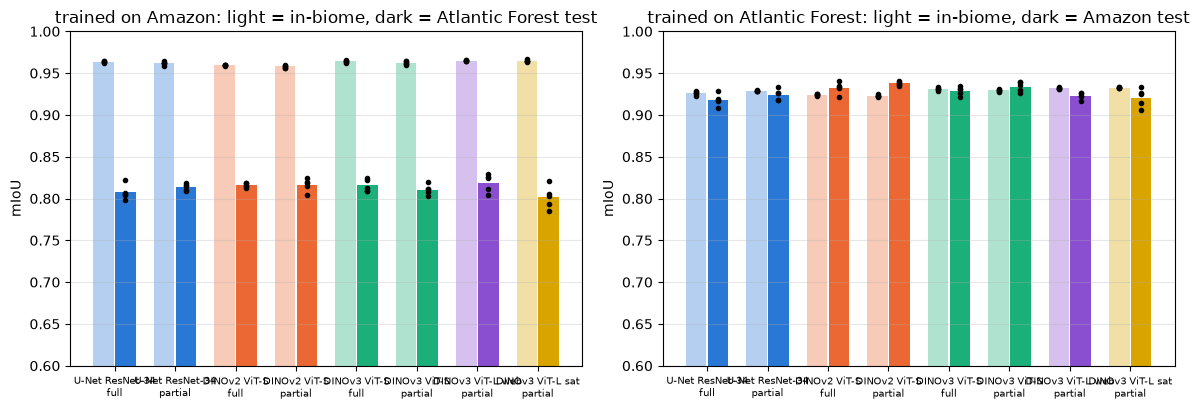

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, (tb, ev_in, ev_out) in zip(axes, [("amazon", "amazon_test", "atlantic_test"), ("atlantic", "atlantic_test", "amazon_test")]):
    for i, m in enumerate(models):
        fam = m.split("_")[0]
        for j, (ev, alpha) in enumerate([(ev_in, 0.35), (ev_out, 1.0)]):
            v = M[(M.model == m) & (M.train_biome == tb) & (M.eval_set == ev)].miou
            xpos = i + (j - 0.5) * 0.36
            ax.bar(xpos, v.mean(), 0.34, color=COLORS[fam], alpha=alpha, edgecolor="none")
            ax.scatter(np.full(len(v), xpos), v, s=9, color="black", zorder=3)
    ax.set_xticks(range(len(models)), [MODEL_NAMES[m].replace(", ", "\n") for m in models], fontsize=7)
    ax.set_title(f"trained on {BIOME[tb]}: light = in-biome, dark = {BIOME[ev_out.split('_')[0]]} test")
    ax.set_ylabel("mIoU"); ax.set_ylim(0.6, 1.0); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "fig1_in_vs_cross.png", dpi=200); plt.show()

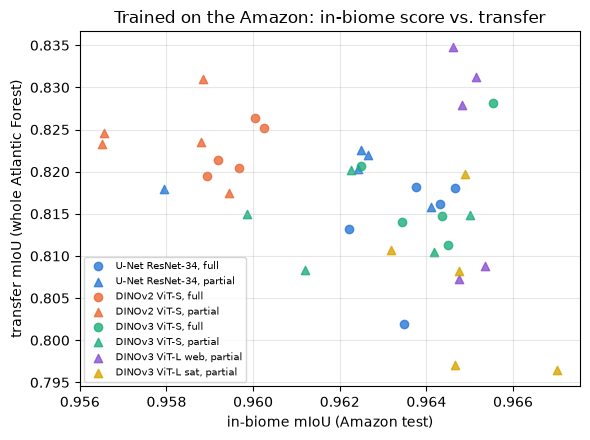

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for m in models:
    fam = m.split("_")[0]
    x = M[(M.model == m) & (M.train_biome == "amazon") & (M.eval_set == "amazon_test")].set_index("seed").miou
    y = M[(M.model == m) & (M.train_biome == "amazon") & (M.eval_set == "atlantic_all")].set_index("seed").miou
    ax.scatter(x, y.reindex(x.index), color=COLORS[fam], marker="o" if m.endswith("_ft") else "^", label=MODEL_NAMES[m], alpha=0.8)
ax.set_xlabel("in-biome mIoU (Amazon test)"); ax.set_ylabel("transfer mIoU (whole Atlantic Forest)")
ax.set_title("Trained on the Amazon: in-biome score vs. transfer"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / "fig2_in_vs_transfer_scatter.png", dpi=200); plt.show()

## 7. Learning curves and convergence

`history/<run>.csv` has one row per validation check (15 per run). Curves are averaged over seeds; the shaded band is ± 1 SD.
Training metrics are pooled over the augmented training crops since the previous check (model in training mode), validation
metrics over the whole validation split of the training biome.

**Convergence check.** If the best validation checkpoint is usually one of the last checks and validation mIoU is still rising,
the schedule is too short and a longer run is needed. We flag a model when, in more than half of its runs, the best checkpoint is
at the last or second-to-last check *and* validation mIoU improved by more than 0.005 over the last three checks.

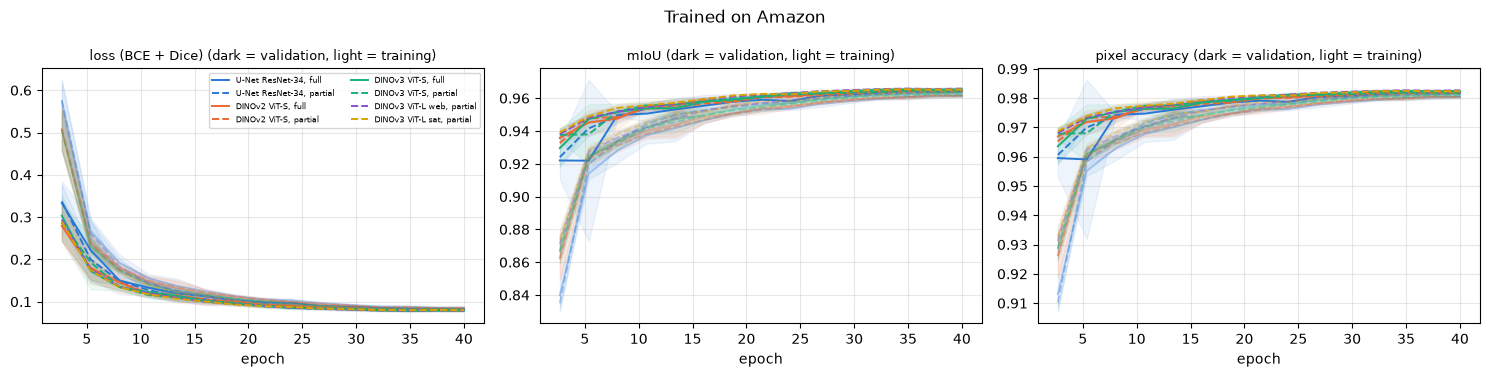

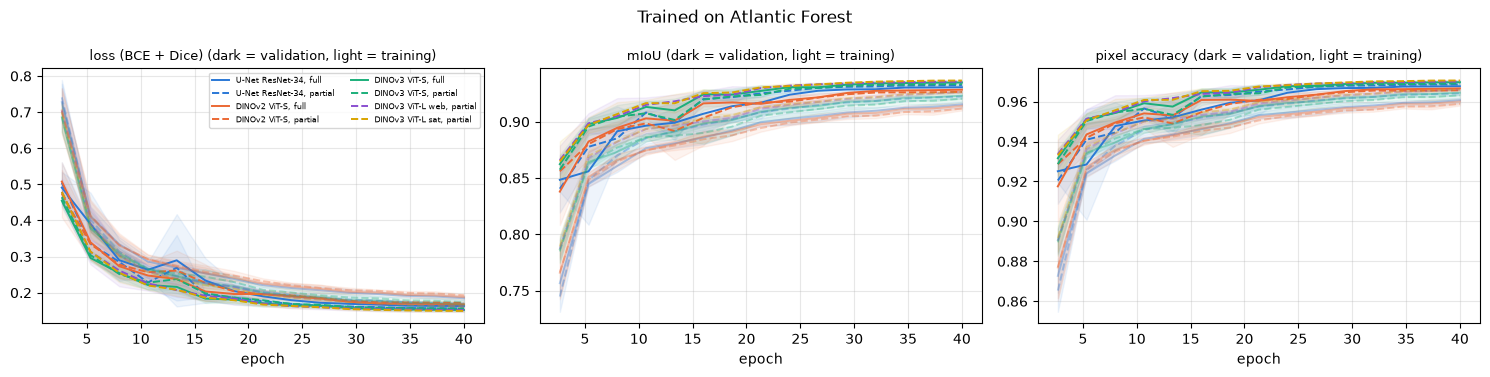

,model,train_biome,median_best_check,n_checks,share_late_and_rising,needs_longer_run
0,dinov2_ft,amazon,15.0,15,0.0,False
1,dinov2_ft,atlantic,15.0,15,0.0,False
2,dinov2_pft,amazon,13.0,15,0.0,False
3,dinov2_pft,atlantic,15.0,15,0.0,False
4,dinov3_ft,amazon,13.0,15,0.0,False
5,dinov3_ft,atlantic,15.0,15,0.0,False
6,dinov3_pft,amazon,14.0,15,0.0,False
7,dinov3_pft,atlantic,15.0,15,0.0,False
8,dinov3l_pft,amazon,15.0,15,0.0,False
9,dinov3l_pft,atlantic,15.0,15,0.0,False


Models flagged for a longer schedule: none


In [11]:
H = pd.concat([pd.read_csv(f).assign(run=f.stem) for f in sorted((RAW / "history").glob("*.csv"))], ignore_index=True)
H = H.merge(runs[["run", "model", "seed", "train_biome"]], on="run")
H.to_csv(TABLES / "history_all.csv", index=False)

curves = [("train_loss", "val_loss", "loss (BCE + Dice)"), ("train_miou", "val_miou", "mIoU"), ("train_acc", "val_acc", "pixel accuracy")]
for tb in BIOME:
    fig, axes = plt.subplots(1, len(curves), figsize=(15, 3.8))
    for ax, (tr, va, label) in zip(axes, curves):
        for m in models:
            g = H[(H.model == m) & (H.train_biome == tb)].groupby("epoch")
            col = COLORS[m.split("_")[0]]; ls = "-" if m.endswith("_ft") else "--"
            for c, a in [(va, 1.0), (tr, 0.35)]:
                mu, sd = g[c].mean(), g[c].std()
                ax.plot(mu.index, mu, ls, color=col, alpha=a, lw=1.4, label=MODEL_NAMES[m] if c == va else None)
                ax.fill_between(mu.index, mu - sd, mu + sd, color=col, alpha=0.08)
        ax.set_xlabel("epoch"); ax.set_title(f"{label} (dark = validation, light = training)", fontsize=9); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=6, ncol=2)
    fig.suptitle(f"Trained on {BIOME[tb]}"); fig.tight_layout()
    fig.savefig(FIGS / f"fig3_learning_curves_{tb}.png", dpi=200); plt.show()

def convergence(g):
    g = g.sort_values("step"); n = len(g)
    best_pos = int(g.val_miou.values.argmax())
    late = best_pos >= n - 2
    rising = n >= 4 and g.val_miou.values[-1] - g.val_miou.values[-4] > 0.005
    return pd.Series(dict(best_check=best_pos + 1, n_checks=n, late_and_rising=late and rising))

CV = H.groupby(["model", "train_biome", "seed"]).apply(convergence, include_groups=False).reset_index()
CONV = CV.groupby(["model", "train_biome"]).agg(median_best_check=("best_check", "median"), n_checks=("n_checks", "first"),
                                                 share_late_and_rising=("late_and_rising", "mean")).reset_index()
CONV["needs_longer_run"] = CONV.share_late_and_rising > 0.5
CONV.to_csv(TABLES / "table6_convergence.csv", index=False)
display(CONV)
print("Models flagged for a longer schedule:", CONV[CONV.needs_longer_run][["model", "train_biome"]].values.tolist() or "none")

## 8. Cost

In [12]:
C = runs.groupby("model").agg(total_M=("total_params", "first"), trained_M=("trainable_params", "first"),
                              train_min=("train_time_s", "mean"), gpu=("gpu", lambda g: ", ".join(sorted(set(g))))).reindex(models)
C[["total_M", "trained_M"]] = (C[["total_M", "trained_M"]] / 1e6).round(1); C["train_min"] = (C.train_min / 60).round(1)
C.index = [MODEL_NAMES[m] for m in C.index]
C.to_csv(TABLES / "table5_cost.csv")
display(C)

,total_M,trained_M,train_min,gpu
"U-Net ResNet-34, full",24.4,24.4,1.5,NVIDIA GeForce RTX 4090
"U-Net ResNet-34, partial",24.4,16.3,1.3,NVIDIA GeForce RTX 4090
"DINOv2 ViT-S, full",27.7,27.7,2.5,NVIDIA GeForce RTX 4090
"DINOv2 ViT-S, partial",27.7,13.4,2.4,NVIDIA GeForce RTX 4090
"DINOv3 ViT-S, full",27.7,27.7,2.3,NVIDIA GeForce RTX 4090
"DINOv3 ViT-S, partial",27.7,13.5,2.2,NVIDIA GeForce RTX 4090
"DINOv3 ViT-L web, partial",314.0,112.4,9.1,NVIDIA GeForce RTX 4090
"DINOv3 ViT-L sat, partial",314.0,112.4,9.0,NVIDIA GeForce RTX 4090


## 9. Findings (generated from the tables above)

In [13]:
a2f = M[(M.train_biome == "amazon") & (M.eval_set == "atlantic_test")].groupby("model").miou.mean().reindex(models)
a2a = M[(M.train_biome == "amazon") & (M.eval_set == "amazon_test")].groupby("model").miou.mean().reindex(models)
a2all = M[(M.train_biome == "amazon") & (M.eval_set == "atlantic_all")].groupby("model").miou.mean().reindex(models)
lines = [f"Seeds: {complete} ({len(complete)}), models: {len(models)}.",
         f"In-biome (Amazon → Amazon) mIoU: {a2a.min():.3f}–{a2a.max():.3f} across models (spread {a2a.max() - a2a.min():.3f}).",
         f"Transfer (Amazon → Atlantic, official test) mIoU: {a2f.min():.3f}–{a2f.max():.3f} (spread {a2f.max() - a2f.min():.3f}); "
         f"best: {MODEL_NAMES[a2f.idxmax()]}.",
         f"Transfer to the whole Atlantic Forest (605 images): best {MODEL_NAMES[a2all.idxmax()]} ({a2all.max():.3f}), "
         f"worst {MODEL_NAMES[a2all.idxmin()]} ({a2all.min():.3f})."]
sig = T3[(T3["Holm p"] < 0.05)]
lines.append("Paired differences with Holm p < 0.05: " + ("; ".join(f"{r['comparison']} ({r['test set']}): {r['mean Δ mIoU']:+.4f}" for _, r in sig.iterrows()) or "none") + ".")
best3b = {ev: g.loc[g["mean Δ mIoU"].idxmax()] for ev, g in T3b.groupby("test set")}
lines.append("Each model vs. U-Net ResNet-34, full (7 comparisons per test set, Holm): " + "; ".join(
    f"{ev}: largest gain {r['comparison'].split(' − ')[0]} {r['mean Δ mIoU']:+.4f}, smallest Holm p {T3b[T3b['test set'] == ev]['Holm p'].min():.3f}"
    for ev, r in best3b.items()) + ".")
piv = M[M.train_biome == "amazon"].pivot_table(index=["model", "seed"], columns="eval_set", values="miou")
for ev in ("atlantic_test", "atlantic_all"):
    r = stats.spearmanr(piv["amazon_test"], piv[ev])
    lines.append(f"Spearman ρ, in-biome (Amazon test) vs. {dir_name('amazon', ev)} mIoU over the {len(piv)} Amazon-trained runs: "
                 f"{r.statistic:+.2f} (p = {r.pvalue:.3f}; runs share seeds and models, so p is approximate).")
text = "\n".join("• " + l for l in lines)
(TABLES / "findings.txt").write_text(text)
print(text)

• Seeds: [0, 1, 2, 3, 4] (5), models: 8.
• In-biome (Amazon → Amazon) mIoU: 0.958–0.965 across models (spread 0.007).
• Transfer (Amazon → Atlantic, official test) mIoU: 0.802–0.819 (spread 0.017); best: DINOv3 ViT-L web, partial.
• Transfer to the whole Atlantic Forest (605 images): best DINOv2 ViT-S, partial (0.824), worst DINOv3 ViT-L sat, partial (0.806).
• Paired differences with Holm p < 0.05: none.
• Each model vs. U-Net ResNet-34, full (7 comparisons per test set, Holm): Amazon → Atlantic Forest: largest gain DINOv3 ViT-L web, partial +0.0116, smallest Holm p 0.289; Amazon → Atlantic Forest (all): largest gain DINOv2 ViT-S, partial +0.0105, smallest Holm p 0.313.
• Spearman ρ, in-biome (Amazon test) vs. Amazon → Atlantic Forest mIoU over the 40 Amazon-trained runs: -0.10 (p = 0.540; runs share seeds and models, so p is approximate).
• Spearman ρ, in-biome (Amazon test) vs. Amazon → Atlantic Forest (all) mIoU over the 40 Amazon-trained runs: -0.31 (p = 0.052; runs share seeds an

## 10. Poster figures

Larger fonts for an A0 poster (drawn at the printed width of one poster column, about 14 inches). Same numbers as above.

- `poster_overview.png`: per model, the mIoU of every seed (small dots) and the mean (large dot) in three settings on one common
  axis: in-biome (Amazon test), Amazon → whole Atlantic Forest, and Atlantic Forest → whole Amazon.
- `poster_delta.png`: paired difference to the U-Net (full fine-tuning) on Amazon → whole Atlantic Forest, per seed and as mean
  with a 95 % t confidence interval (not adjusted for multiple comparisons; the Holm-adjusted tests of these 7 comparisons
  are in Table 3b).

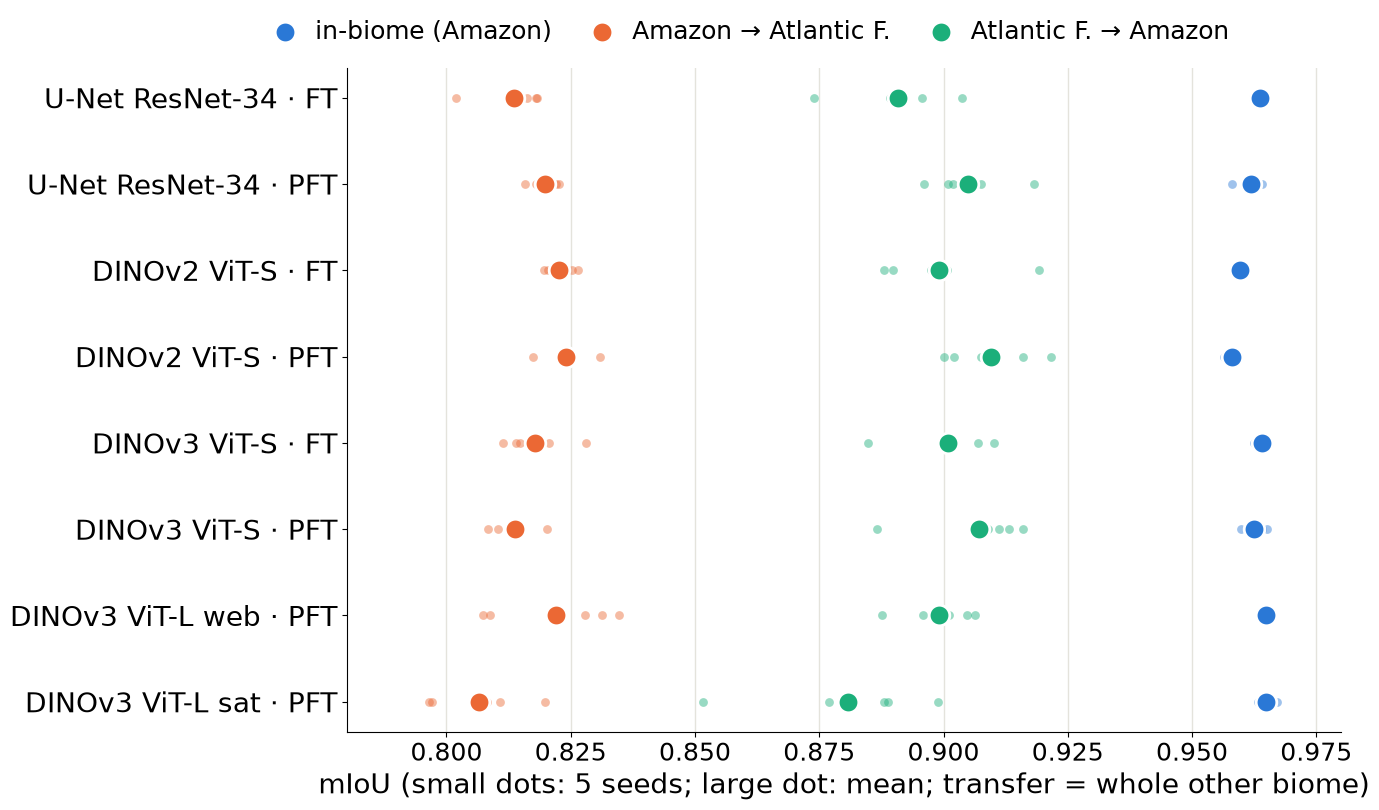

In [14]:
SHORT = {m: MODEL_NAMES[m].replace(", full", " · FT").replace(", partial", " · PFT").replace("satellite", "sat") for m in models}
PAL = {"in": "#2a78d6", "a2f": "#eb6834", "f2a": "#1baf7a"}   # validated categorical slots 1-3 (dataviz palette)
plt.rcParams.update({"font.size": 20, "axes.titlesize": 22, "axes.labelsize": 20, "xtick.labelsize": 18, "ytick.labelsize": 20,
                     "legend.fontsize": 18, "axes.spines.top": False, "axes.spines.right": False})
settings = [("in", "amazon", "amazon_test", "in-biome (Amazon)"),
            ("a2f", "amazon", "atlantic_all", "Amazon → Atlantic F."),
            ("f2a", "atlantic", "amazon_all", "Atlantic F. → Amazon")]
fig, ax = plt.subplots(figsize=(14, 8.5))
ys = {m: len(models) - 1 - i for i, m in enumerate(models)}
for key, tb, ev, label in settings:
    d = M[(M.train_biome == tb) & (M.eval_set == ev)]
    for m in models:
        v = d[d.model == m].miou.to_numpy()
        ax.scatter(v, np.full(len(v), ys[m]), s=40, color=PAL[key], alpha=0.45, linewidths=0, zorder=2)
        ax.scatter([v.mean()], [ys[m]], s=220, color=PAL[key], edgecolors="white", linewidths=2, zorder=3,
                   label=label if m == models[0] else None)
ax.set_yticks(list(ys.values()), [SHORT[m] for m in ys])
ax.set_xlim(0.78, 0.98); ax.set_xlabel("mIoU (small dots: 5 seeds; large dot: mean; transfer = whole other biome)")
ax.grid(axis="x", color="#e4e3dc", linewidth=1); ax.set_axisbelow(True)
ax.legend(loc="lower center", bbox_to_anchor=(0.4, 1.0), ncol=3, frameon=False, handletextpad=0.2, columnspacing=1.0)
fig.tight_layout()
fig.savefig(FIGS / "poster_overview.png", dpi=200)
plt.show()

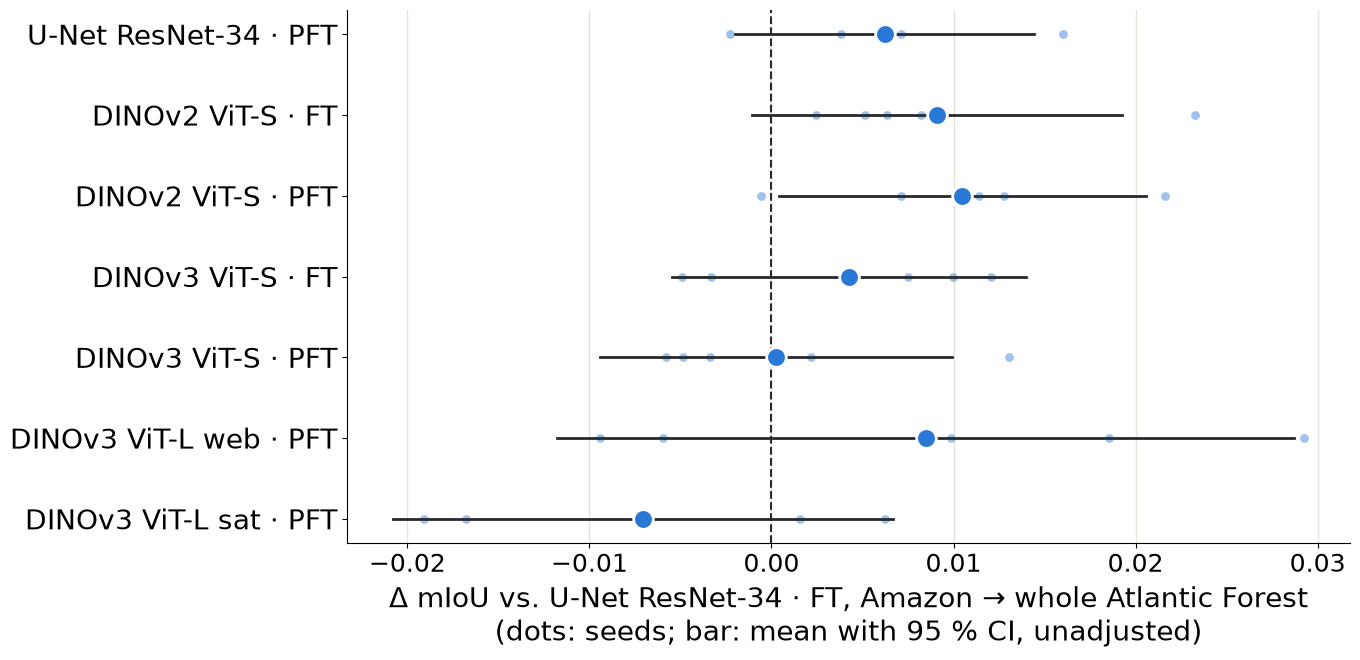

In [15]:
d = M[(M.train_biome == "amazon") & (M.eval_set == "atlantic_all")].pivot(index="seed", columns="model", values="miou")
ref = "unet_ft"
fig, ax = plt.subplots(figsize=(14, 7))
others = [m for m in models if m != ref]
for i, m in enumerate(others):
    y = len(others) - 1 - i
    diff = (d[m] - d[ref]).dropna()
    mean, half = diff.mean(), stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))
    ax.scatter(diff, np.full(len(diff), y), s=40, color="#2a78d6", alpha=0.45, linewidths=0, zorder=2)
    ax.plot([mean - half, mean + half], [y, y], color="#28282d", linewidth=2, zorder=3)
    ax.scatter([mean], [y], s=200, color="#2a78d6", edgecolors="white", linewidths=2, zorder=4)
ax.axvline(0, color="#28282d", linewidth=1.5, linestyle="--", zorder=1)
ax.set_yticks(range(len(others) - 1, -1, -1), [SHORT[m] for m in others])
ax.set_xlabel(f"Δ mIoU vs. {SHORT[ref]}, Amazon → whole Atlantic Forest\n(dots: seeds; bar: mean with 95 % CI, unadjusted)")
ax.grid(axis="x", color="#e4e3dc", linewidth=1); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGS / "poster_delta.png", dpi=200)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)